# Conditional utility of contextual politeness

## Phase 5A · Relative reply length

How much does adding the 256-token Polite Guard score change prediction accuracy when two replies are similar in length? The primary comparison adds the score to the ConvoKit-ablated baseline (P6a → P6c). A secondary comparison adds the same score to full P6 (P6 → P6e). Both use the existing out-of-fold predictions on 3,451 matched training pairs.

The relative length gap is the absolute difference in archived opening word counts divided by the longer opening’s word count. The four bands are 0–10%, above 10% through 25%, above 25% through 50%, and above 50% through 100%. Accuracy uses a 0.5 threshold for an A win.

For the 95% intervals, resample whole original-poster discussions 1,000 times and use the same sampled discussions for both models and all length bands. Compute gains in accuracy within each draw. The direct contrast subtracts the gain in the farthest-apart length band from the gain in the closest band. The intervals are pointwise and describe variation across the observed discussions with predictions held fixed.

[Length-conditioned analysis runner](analyze_length_conditioned_politeness.py)

In [1]:
from pathlib import Path
import json

import pandas as pd

project = next(
    path / "project" for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "team-setup").is_dir()
)
run_id = "20261124T060814527201Z"
run = project / "data/processed/linguistic-features/paired-models/p6_politeness_baseline_integration" / run_id
length_analysis = run / "analysis/length_conditioned"
length_manifest = json.loads((length_analysis / "length_analysis_metadata.json").read_text())
assert length_manifest["split"] == "train"

length_table = pd.read_csv(length_analysis / "length_accuracy.csv")
fields = ["baseline_accuracy", "extended_accuracy", "change", "ci_low", "ci_high"]
length_table[fields] *= 100
print(length_table.rename(columns={
    "baseline_accuracy": "Baseline (%)", "extended_accuracy": "With politeness (%)",
    "change": "Change (pp)", "ci_low": "95% lower (pp)", "ci_high": "95% upper (pp)",
}).round(2).to_string(index=False))
print()
length_contrasts = pd.read_csv(length_analysis / "length_contrasts.csv")
contrast_fields = ["difference_in_gains", "ci_low", "ci_high"]
length_contrasts[contrast_fields] *= 100
print("Difference in accuracy gains between the closest- and farthest-length bands (pp)")
print(length_contrasts.round(2).to_string(index=False))


baseline extended length_band  pairs  discussions  Baseline (%)  With politeness (%)  Change (pp)  95% lower (pp)  95% upper (pp)
     P6a      P6c       0–10%    382          360         59.42                60.21         0.79           -0.77            2.36
     P6a      P6c     >10–25%    639          584         64.79                64.48        -0.31           -1.11            0.34
     P6a      P6c     >25–50%   1247         1072         66.08                66.80         0.72           -0.16            1.60
     P6a      P6c    >50–100%   1183         1039         74.89                75.23         0.34           -0.17            0.84
      P6      P6e       0–10%    382          360         58.64                58.38        -0.26           -1.93            1.10
      P6      P6e     >10–25%    639          584         64.16                64.32         0.16           -0.78            1.14
      P6      P6e     >25–50%   1247         1072         66.00                65.68      

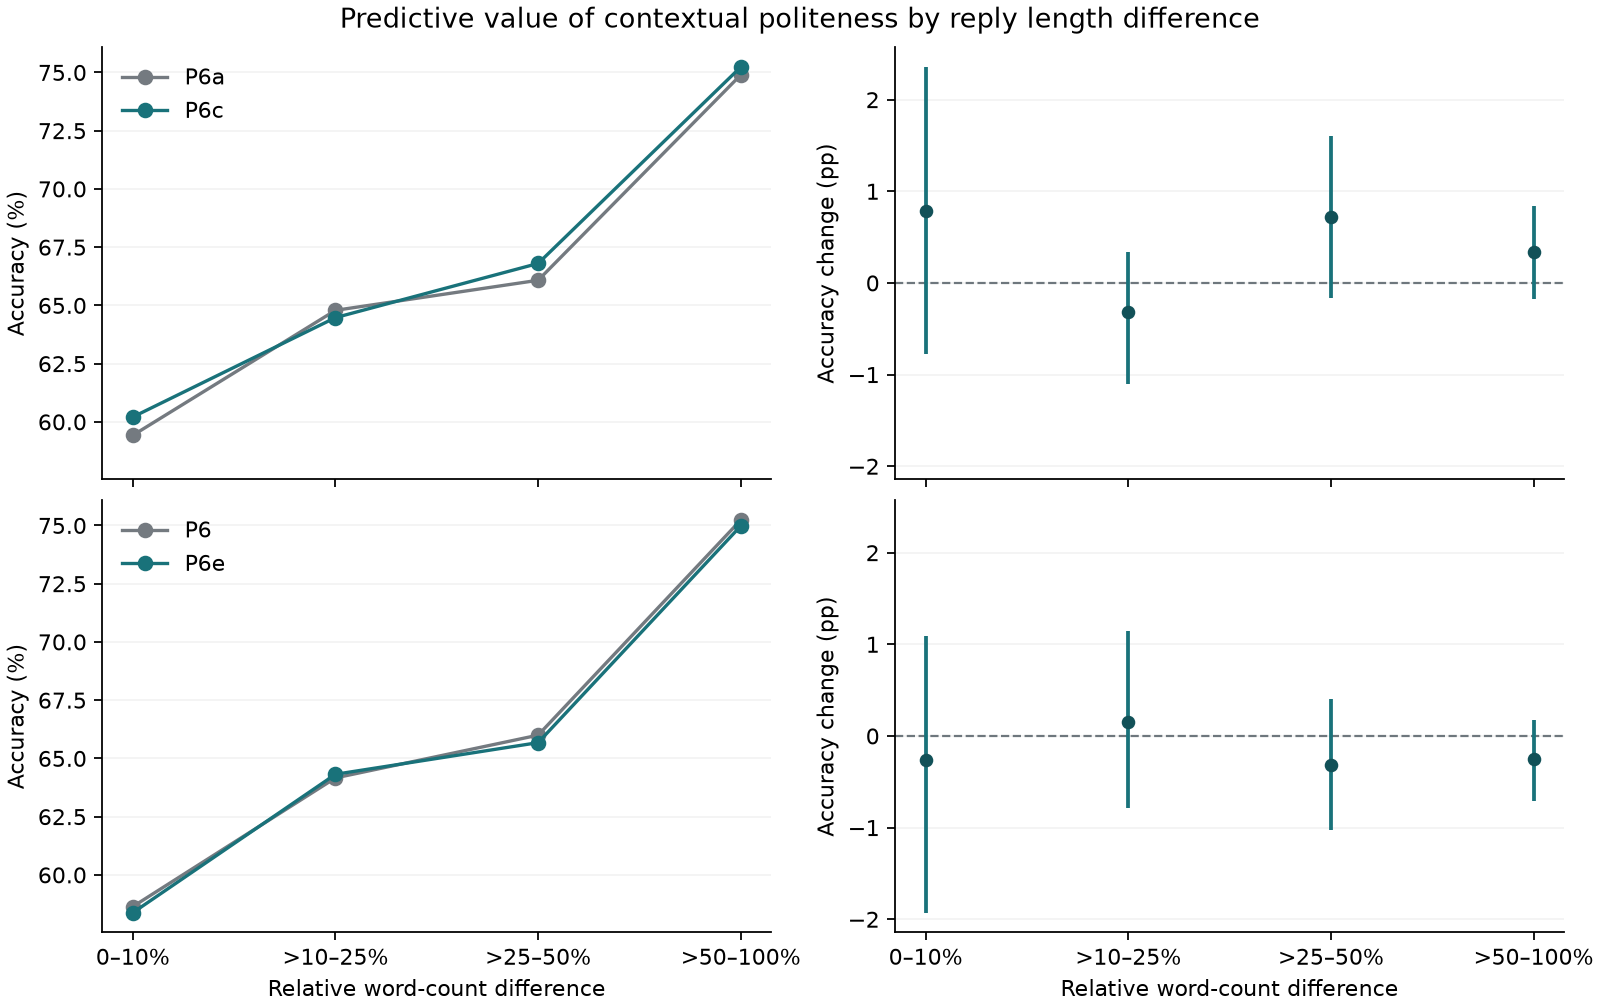

In [2]:
from IPython.display import Image, display

display(Image(filename=str(length_analysis / "length_conditioned_performance.png"),
              alt="Baseline and extended model accuracy and 95% paired intervals across reply-length bands"))


### What the length analysis shows

- **P6a was less accurate for similar-length pairs.** Accuracy was 59.42% for the 382 pairs within 10% of each other and 74.89% when the gap exceeded 50%.
- **The 256-token score added three correct picks in the closest band.** P6c reached 60.21% accuracy there, a gain of 0.79 percentage points (95% CI −0.77 to +2.36). Its gain was 0.45 points larger in the closest band than in the farthest band, with a 95% interval of −1.12 to +2.02 points.
- **Full P6 showed no similar-length gain.** Adding the same score changed accuracy in the closest band by −0.26 points (95% CI −1.93 to +1.10). Every band-level interval for both comparisons included zero.

The observed gains do not establish that contextual politeness is more useful when replies are similar in length.

## Phase 5B · Politeness score margin

Group pairs by the absolute difference between their saved 256-token Polite Guard scores. The four non-tied bands end at 0.25, 0.50, 1.00, and 3.00, with each upper endpoint included. Pairs with an absolute difference at most 1e-9 are reported separately as ties. The higher-score win rate describes the model’s estimated politeness.

Compare P6a with P6c, then P6 with P6e, using the same out-of-fold predictions as Phase 5A. Within each band, report the higher-score win rate and changes in ROC-AUC, pairwise accuracy, and log loss. Paired intervals use 1,000 resamples of whole discussions and the same weights for every model and band. The direct contrast compares the largest and smallest non-tied bands. The single tied pair is reported as a count.

[Margin analysis runner](analyze_politeness_margin.py)

In [3]:
margin_analysis = run / "analysis/politeness_margin"
margin_rates = pd.read_csv(margin_analysis / "higher_score_win_rate.csv")
margin_performance = pd.read_csv(margin_analysis / "incremental_performance.csv")
margin_contrasts = pd.read_csv(margin_analysis / "margin_contrasts.csv")
margin_ties = pd.read_csv(margin_analysis / "ties.csv")

print("How often the higher-scoring reply won (%)")
rates = margin_rates.copy()
rate_fields = ["win_rate", "ci_low", "ci_high"]
rates[rate_fields] *= 100
print(rates.round(2).to_string(index=False))
print()
print("Pairwise accuracy and change (accuracy in %, change and interval in pp)")
accuracy = margin_performance.loc[margin_performance["metric"].eq("Pairwise accuracy")].drop(columns="metric")
fields = ["baseline_value", "extended_value", "change", "ci_low", "ci_high"]
accuracy[fields] *= 100
print(accuracy.round(2).to_string(index=False))
print()
print("ROC-AUC and log-loss changes")
other = margin_performance.loc[margin_performance["metric"].ne("Pairwise accuracy")]
print(other.round(4).to_string(index=False))
print()
print("Large margin minus nearly equal margin (pp)")
contrasts = margin_contrasts.copy()
contrast_fields = ["large_minus_nearly_equal", "ci_low", "ci_high"]
contrasts[contrast_fields] *= 100
print(contrasts.round(2).to_string(index=False))
print()
print("Tied-score pairs")
print(margin_ties.to_string(index=False))


How often the higher-scoring reply won (%)
    margin  pairs  discussions  higher_score_wins  win_rate  ci_low  ci_high
     ≤0.25   1671         1391                903     54.04   51.48    56.41
>0.25–0.50    463          440                267     57.67   52.74    61.87
>0.50–1.00    567          528                323     56.97   52.89    61.03
>1.00–3.00    749          662                432     57.68   54.03    61.38

Pairwise accuracy and change (accuracy in %, change and interval in pp)
baseline extended     margin  baseline_value  extended_value  change  ci_low  ci_high
     P6a      P6c      ≤0.25           67.50           67.44   -0.06   -0.48     0.37
     P6a      P6c >0.25–0.50           70.63           70.63    0.00   -0.84     0.86
     P6a      P6c >0.50–1.00           67.72           68.78    1.06   -0.18     2.32
     P6a      P6c >1.00–3.00           68.36           69.56    1.20   -0.13     2.66
      P6      P6e      ≤0.25           66.91           67.09    0.18 

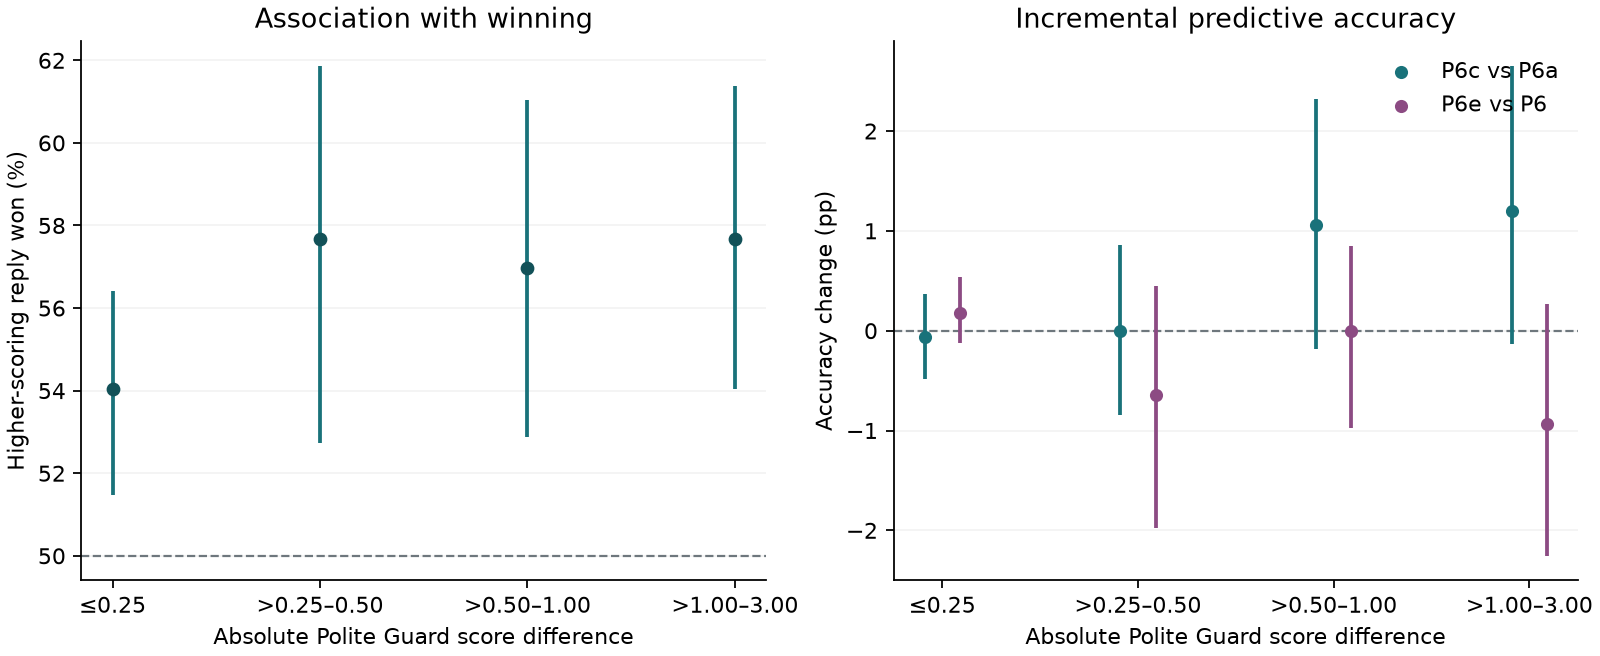

In [4]:
display(Image(filename=str(margin_analysis / "politeness_margin.png"),
              alt="Higher-scoring reply win rates and accuracy changes by Polite Guard score margin"))


### What the margin analysis shows

- **The higher-scoring reply won more often in every non-tied band.** It won 54.04% of the 1,671 pairs in the smallest band and 57.68% of the 749 in the largest. The 3.64-percentage-point difference between those bands was uncertain (95% CI −0.67 to +8.05 points).
- **The strongest accuracy gain for P6a was in the largest band.** Adding the 256-token score raised accuracy by 1.20 points (95% CI −0.13 to +2.66). The gain was 1.26 points larger than in the smallest band (95% CI −0.20 to +2.75).
- **The full-baseline comparison showed a different pattern.** P6e lost 0.93 accuracy points relative to P6 in the largest band (95% CI −2.25 to +0.27). All within-band intervals for changes in accuracy, ROC-AUC, and log loss included zero.

The marginal win-rate association and the incremental prediction results answer different questions. The band analysis provides no clear evidence that larger Polite Guard score differences improve prediction after the baseline features are included.

## Phase 5C · Baseline confidence

Confidence is the larger of the two probabilities assigned to A or B by the baseline’s out-of-fold model. The three bands are 50–60%, above 60% through 80%, and above 80% through 100%. Assign bands separately for P6a and P6, then compare each with the model that adds the 256-token Polite Guard score.

A corrected pick goes from wrong to correct, and a new error goes from correct to wrong. Conditional correction rates use baseline errors as their denominator. Conditional new-error rates use correct baseline picks. The matrix percentages use all pairs in the indicated band.

Paired 95% intervals for accuracy changes use 1,000 resamples of whole discussions with the same weights for both models. The low-minus-high contrast compares accuracy gains in the least and most confident bands. If no picks change in a band, its fixed-prediction bootstrap interval is zero by construction.

[Baseline confidence runner](analyze_baseline_confidence.py)

In [5]:
confidence_analysis = run / "analysis/baseline_confidence"
confidence_table = pd.read_csv(confidence_analysis / "confidence_accuracy.csv")
confidence_contrasts = pd.read_csv(confidence_analysis / "confidence_contrasts.csv")

print("Agreement and disagreement counts")
fields = ["baseline", "extended", "confidence_band", "pairs", "discussions",
          "both_correct", "corrected", "new_error", "both_wrong"]
print(confidence_table[fields].to_string(index=False))
print()
print("Accuracy and conditional error rates (%) and accuracy changes (pp)")
rates = confidence_table.rename(columns={
    "baseline_accuracy": "Baseline (%)", "extended_accuracy": "With politeness (%)",
    "corrected_share_of_baseline_errors": "Baseline errors corrected (%)",
    "new_error_share_of_baseline_correct": "Baseline correct made wrong (%)",
    "accuracy_change": "Change (pp)", "ci_low": "95% lower (pp)", "ci_high": "95% upper (pp)",
})
rate_fields = ["Baseline (%)", "With politeness (%)", "Baseline errors corrected (%)",
               "Baseline correct made wrong (%)", "Change (pp)", "95% lower (pp)", "95% upper (pp)"]
rates[rate_fields] *= 100
print(rates[["baseline", "extended", "confidence_band", *rate_fields]].round(2).to_string(index=False))
print()
print("Low-confidence accuracy gain minus high-confidence gain (pp)")
contrast = confidence_contrasts.copy()
contrast[["low_minus_high_accuracy_change", "ci_low", "ci_high"]] *= 100
print(contrast.round(2).to_string(index=False))


Agreement and disagreement counts
baseline extended confidence_band  pairs  discussions  both_correct  corrected  new_error  both_wrong
     P6a      P6c          50–60%   1153         1008           620         36         22         475
     P6a      P6c         >60–80%   1689         1416          1185          0          0         504
     P6a      P6c        >80–100%    609          561           524          0          0          85
      P6      P6e          50–60%   1134         1006           604         20         27         483
      P6      P6e         >60–80%   1689         1418          1178          0          0         511
      P6      P6e        >80–100%    628          578           538          0          0          90

Accuracy and conditional error rates (%) and accuracy changes (pp)
baseline extended confidence_band  Baseline (%)  With politeness (%)  Baseline errors corrected (%)  Baseline correct made wrong (%)  Change (pp)  95% lower (pp)  95% upper (pp)
     P

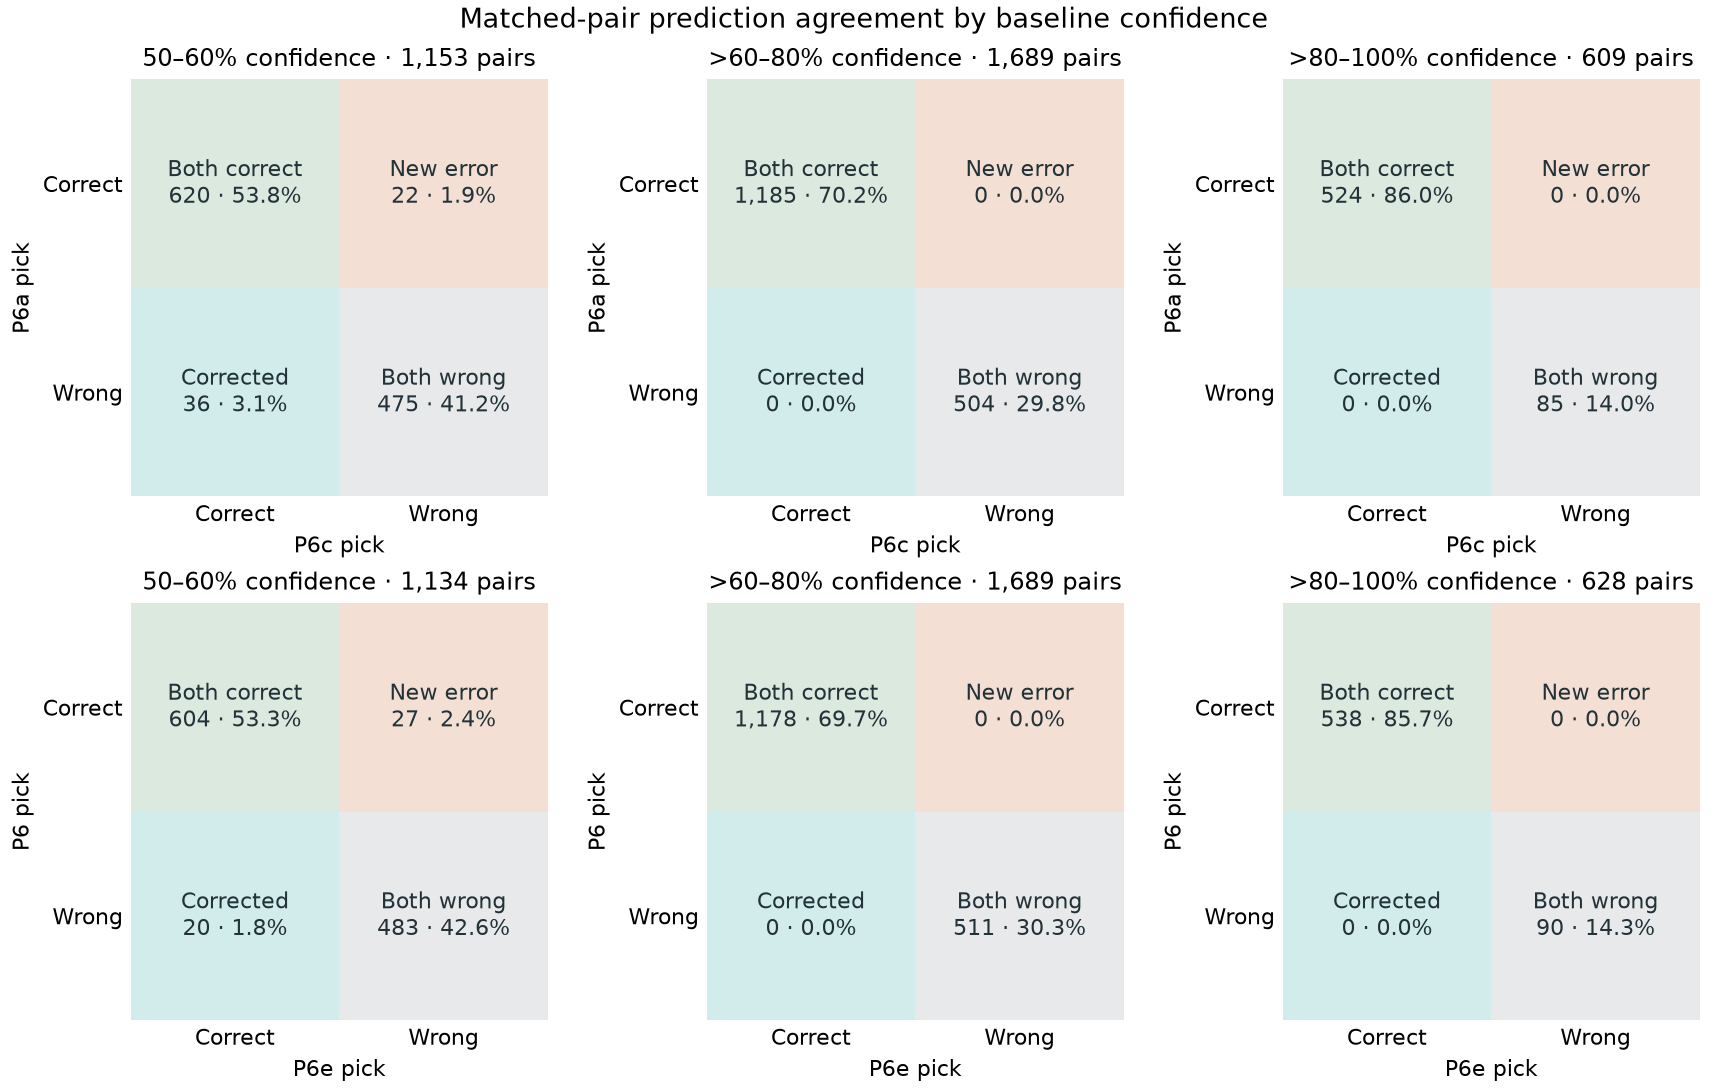

In [6]:
display(Image(filename=str(confidence_analysis / "model_disagreement_matrix.png"),
              alt="Six agreement matrices for the two baseline comparisons across three confidence bands"))


### What the confidence analysis shows

- **Every changed pick was in the 50–60% confidence band.** Neither comparison changed a pick above 60% confidence among these training pairs.
- **P6c corrected more errors than it introduced.** It fixed 36 of P6a’s 511 low-confidence errors (7.05%) and overturned 22 of its 642 correct picks (3.43%). Accuracy rose from 55.68% to 56.90%, a gain of 1.21 percentage points (95% CI −0.08 to +2.49).
- **P6e introduced more errors than it corrected.** It fixed 20 of P6’s 503 low-confidence errors (3.98%) and overturned 27 of its 631 correct picks (4.28%). The resulting change was −0.62 points (95% CI −1.77 to +0.52).

The score changed decisions where the baseline was near its decision threshold. The net accuracy effect in that band remains uncertain.